In [1]:
%pip install -U datasets pandas

  Using cached pyarrow-26.0.0-cp314-cp314-win_amd64.whl.metadata (3.0 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
   ---------------------------------------- 0.0/604.4 kB ? eta -:--:--
   ---------------------------------------- 0.0/604.4 kB ? eta -:--:--
   ----------------- ---------------------- 262.1/604.4 kB ? eta -:--:--
   ---------------------------------------- 604.4/604.4 kB 1.7 MB/s  0:00:00
   ---------------------------------------- 0.0/839.9 kB ? eta -:--:--
   ------------------------ --------------- 524.3/839.9 kB 3.9 MB/s eta 0:00:01
   ---------------------------------------- 839.9/839.9 kB 2.0 MB/s  0:00:00
Using cached click-8.5.0-py3-none-any.whl (125 kB)
   ---------------------------------------- 0.0/3.8 MB ? eta -:--:--
   -------- ------------------------------- 0.8/3.8 MB 4.4 MB/s eta 0:00:01
   ------------- -------------------------- 1.3/3.8 MB 3.0 MB/s eta 0:00:01
   ---------------- ----------------------- 1.6/3.8 MB 2.8 MB/s eta 0:00

In [2]:
from datasets import load_dataset

dataset = load_dataset("bvk/ENRON-spam")

print(dataset)

README.md:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

C:\Users\alimu\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\alimu\.cache\huggingface\hub\datasets--bvk--ENRON-spam. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Repo card metadata block was not found. Setting CardData to empty.
C:\Users\alimu\anaconda3\Lib\site-packages\huggingface_hub\f

Enron_Txt_fn.csv: reconstructing file:   0%|          |  0.00B / 49.1MB            

Enron_Txt_fn.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/33716 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['label', 'email', 'filename'],
        num_rows: 33716
    })
})


In [3]:
print(dataset["train"].column_names)
print(dataset["train"][0])

['label', 'email', 'filename']
{'label': 0, 'email': "['Subject: christmas tree farm pictures  \\n']", 'filename': '0001.1999-12-10.farmer.ham.txt'}


In [5]:
import pandas as pd

print("Dataset splits:", list(dataset.keys()))

for split_name, split_data in dataset.items():
    print(f"\nSplit: {split_name}")
    print("Total emails:", len(split_data))
    print("Columns:", split_data.column_names)

Dataset splits: ['train']

Split: train
Total emails: 33716
Columns: ['label', 'email', 'filename']


In [6]:
split_name = list(dataset.keys())[0]
df = dataset[split_name].to_pandas()

display(df.head())

,label,email,filename
0,0,['Subject: christmas tree farm pictures \n'],0001.1999-12-10.farmer.ham.txt
1,0,['Subject: re : rankings \nthank you .'],0001.1999-12-10.kaminski.ham.txt
2,0,['Subject: leadership development pilot \nsal...,0001.2000-01-17.beck.ham.txt
3,0,"[""Subject: key dates and impact of upcoming sa...",0001.2000-06-06.lokay.ham.txt
4,0,['Subject: key hr issues going forward \na ) ...,0001.2001-02-07.kitchen.ham.txt


In [7]:
print("Available labels:")
for column in df.columns:
    print(f"\nColumn: {column}")
    print(df[column].value_counts(dropna=False).head(10))

Available labels:

Column: label
label
1    17171
0    16545
Name: count, dtype: int64

Column: email
email
['Subject:   \n']                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           

In [8]:
# Check dataset size
print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Check label distribution
print("\nLabel Distribution:")
print(df["label"].value_counts())

# Check label data types
print("\nLabel Data Type:", df["label"].dtype)

Dataset Shape: (33716, 3)

Missing Values:
label       0
email       0
filename    0
dtype: int64

Duplicate Rows: 0

Label Distribution:
label
1    17171
0    16545
Name: count, dtype: int64

Label Data Type: int64


In [9]:
# Display filenames for each label

print("Label 0 — Sample filenames:")
display(df.loc[df["label"] == 0, ["label", "filename"]].head(10))

print("\nLabel 1 — Sample filenames:")
display(df.loc[df["label"] == 1, ["label", "filename"]].head(10))

Label 0 — Sample filenames:


,label,filename
0,0,0001.1999-12-10.farmer.ham.txt
1,0,0001.1999-12-10.kaminski.ham.txt
2,0,0001.2000-01-17.beck.ham.txt
3,0,0001.2000-06-06.lokay.ham.txt
4,0,0001.2001-02-07.kitchen.ham.txt
5,0,0001.2001-04-02.williams.ham.txt
6,0,0002.1999-12-13.farmer.ham.txt
7,0,0002.2001-02-07.kitchen.ham.txt
8,0,0003.1999-12-10.kaminski.ham.txt
9,0,0003.1999-12-14.farmer.ham.txt



Label 1 — Sample filenames:


,label,filename
16545,1,0002.2001-05-25.SA_and_HP.spam (2).txt
16546,1,0002.2001-05-25.SA_and_HP.spam.txt
16547,1,0002.2003-12-18.GP.spam.txt
16548,1,0002.2004-08-01.BG.spam.txt
16549,1,0003.2003-12-18.GP.spam.txt
16550,1,0003.2004-08-01.BG.spam.txt
16551,1,0004.2001-06-12.SA_and_HP.spam.txt
16552,1,0004.2004-08-01.BG.spam (2).txt
16553,1,0004.2004-08-01.BG.spam.txt
16554,1,0005.2001-06-23.SA_and_HP.spam.txt


In [10]:
for label in sorted(df["label"].unique()):
    print(f"\n{'=' * 50}")
    print(f"Label: {label}")
    print("=" * 50)

    samples = df.loc[df["label"] == label, "email"].head(3)

    for i, email in enumerate(samples, start=1):
        print(f"\nEmail {i}:")
        print(str(email)[:700])


Label: 0

Email 1:
['Subject: christmas tree farm pictures  \n']

Email 2:
['Subject: re : rankings  \nthank you .']

Email 3:
['Subject: leadership development pilot  \nsally :\nwhat timing , ask and you shall receive . as per our discussion , listed below\nis an update on the leadership pilot . your vendor selection team will\nreceive an update and even more information later in the week .\non the lunch & learn for energy operations , the audience and focus will be\nyour group . we are ready to start up when appropriate .\nthank you for your time today . please call me if you have any questions at\nx 33597 .\n- - - - - - - - - - - - - - - - - - - - - - forwarded by julie armstrong / corp / enron on 01 / 17 / 2000\n06 : 44 pm - - - - - - - - - - - - - - - - - - - - - - - - - - -\nfrom : susan runkel @ ect 01 / 17 /

Label: 1

Email 1:
['Subject: fw : this is the solution i mentioned lsc  \noo\nthank you ,\nyour email address was obtained from a purchased list ,\nreference # 2020 mid 

label_name
Spam    17171
Ham     16545
Name: count, dtype: int64


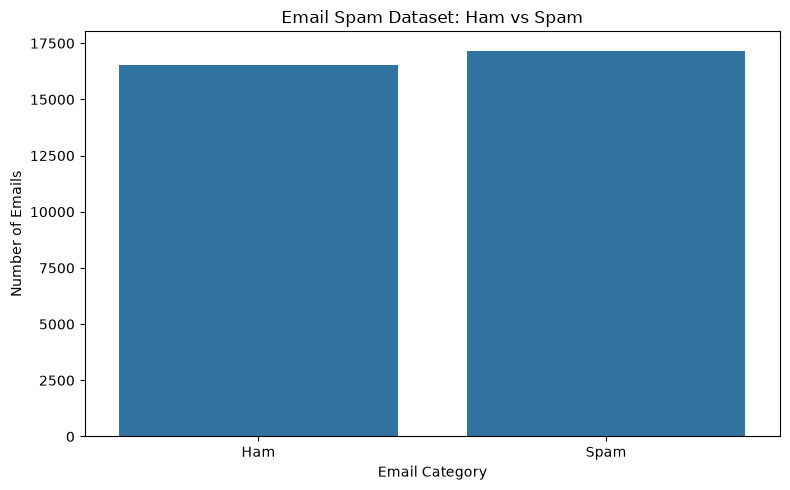

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert numeric labels to readable names
label_names = {0: "Ham", 1: "Spam"}
df["label_name"] = df["label"].map(label_names)

# Count emails in each category
print(df["label_name"].value_counts())

# Plot distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="label_name")

plt.title("Email Spam Dataset: Ham vs Spam")
plt.xlabel("Email Category")
plt.ylabel("Number of Emails")
plt.tight_layout()
plt.show()

In [12]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [13]:
label_percentages = (
    df["label_name"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Class Distribution (%):")
print(label_percentages)

Class Distribution (%):
label_name
Spam    50.93
Ham     49.07
Name: proportion, dtype: float64


In [14]:
# Create a working copy
df = df.copy()

# Convert email content to clean strings
df["email"] = df["email"].apply(
    lambda x: " ".join(x) if isinstance(x, list) else str(x)
)

# Remove missing or empty email text
df = df.dropna(subset=["email"])
df = df[df["email"].str.strip() != ""]

# Reset index
df = df.reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nSample email:")
print(df["email"].iloc[0])

Dataset shape: (33716, 4)

Sample email:
['Subject: christmas tree farm pictures  \n']


In [15]:
import ast

def extract_email_text(value):
    # Convert list-like strings into actual Python objects
    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, list):
                return " ".join(str(item) for item in parsed)
        except (ValueError, SyntaxError):
            pass

    if isinstance(value, list):
        return " ".join(str(item) for item in value)

    return str(value)

df["email"] = df["email"].apply(extract_email_text)

print("Dataset shape:", df.shape)
print("\nSample email:")
print(df["email"].iloc[0])

print("\nData type:", type(df["email"].iloc[0]))

Dataset shape: (33716, 4)

Sample email:
Subject: christmas tree farm pictures  


Data type: <class 'str'>


In [16]:
import re

def clean_email(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove extra spaces and newlines
    text = re.sub(r"\s+", " ", text)

    # Remove spaces from beginning and end
    text = text.strip()

    return text


# Apply cleaning
df["clean_email"] = df["email"].apply(clean_email)

# Compare original and cleaned emails
print("ORIGINAL EMAIL:")
print(df["email"].iloc[0])

print("\nCLEANED EMAIL:")
print(df["clean_email"].iloc[0])

print("\nDataset shape:", df.shape)

ORIGINAL EMAIL:
Subject: christmas tree farm pictures  


CLEANED EMAIL:
subject: christmas tree farm pictures

Dataset shape: (33716, 5)


In [17]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [18]:
import nltk

nltk.download("stopwords")

from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

print("Total English stopwords:", len(stop_words))
print("Sample stopwords:", list(stop_words)[:20])

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\alimu\AppData\Roaming\nltk_data...


Total English stopwords: 198
Sample stopwords: ["he'd", 'her', 'a', "she'll", 'i', 'out', "wasn't", 'can', 'myself', 'will', 'haven', 'them', 'hadn', 'own', 'couldn', 'of', "it'll", 'but', 'too', 'very']


[nltk_data]   Unzipping corpora\stopwords.zip.


In [19]:
import re

def tokenize_email(text):
    # Extract words and numbers from email text
    tokens = re.findall(r"\b[a-z0-9]+\b", text.lower())
    return tokens


# Test on one email
sample_email = df["clean_email"].iloc[0]

tokens = tokenize_email(sample_email)

print("Cleaned Email:")
print(sample_email)

print("\nTokens:")
print(tokens)

print("\nTotal Tokens:", len(tokens))

Cleaned Email:
subject: christmas tree farm pictures

Tokens:
['subject', 'christmas', 'tree', 'farm', 'pictures']

Total Tokens: 5


In [20]:
# Remove English stopwords from tokens
def remove_stopwords(tokens):
    return [
        word for word in tokens
        if word not in stop_words
    ]


# Test on one email
sample_email = df["clean_email"].iloc[0]

tokens = tokenize_email(sample_email)
filtered_tokens = remove_stopwords(tokens)

print("Original Tokens:")
print(tokens)

print("\nTokens After Stopword Removal:")
print(filtered_tokens)

print("\nOriginal Token Count:", len(tokens))
print("Filtered Token Count:", len(filtered_tokens))

Original Tokens:
['subject', 'christmas', 'tree', 'farm', 'pictures']

Tokens After Stopword Removal:
['subject', 'christmas', 'tree', 'farm', 'pictures']

Original Token Count: 5
Filtered Token Count: 5


In [21]:
# Apply tokenization to all emails
df["tokens"] = df["clean_email"].apply(tokenize_email)

# Apply stopword removal
df["filtered_tokens"] = df["tokens"].apply(remove_stopwords)

# Join tokens back into text for later ML use
df["processed_email"] = df["filtered_tokens"].apply(
    lambda tokens: " ".join(tokens)
)

# Display results
display(
    df[["clean_email", "tokens", "filtered_tokens", "processed_email"]].head(5)
)

,clean_email,tokens,filtered_tokens,processed_email
0,subject: christmas tree farm pictures,"[subject, christmas, tree, farm, pictures]","[subject, christmas, tree, farm, pictures]",subject christmas tree farm pictures
1,subject: re : rankings thank you .,"[subject, re, rankings, thank, you]","[subject, rankings, thank]",subject rankings thank
2,subject: leadership development pilot sally : ...,"[subject, leadership, development, pilot, sall...","[subject, leadership, development, pilot, sall...",subject leadership development pilot sally tim...
3,subject: key dates and impact of upcoming sap ...,"[subject, key, dates, and, impact, of, upcomin...","[subject, key, dates, impact, upcoming, sap, i...",subject key dates impact upcoming sap implemen...
4,subject: key hr issues going forward a ) year ...,"[subject, key, hr, issues, going, forward, a, ...","[subject, key, hr, issues, going, forward, yea...",subject key hr issues going forward year end r...


In [22]:
# Calculate token counts before and after stopword removal
df["original_token_count"] = df["tokens"].apply(len)
df["filtered_token_count"] = df["filtered_tokens"].apply(len)

print("Total Emails:", len(df))

print("\nAverage tokens before stopword removal:")
print(round(df["original_token_count"].mean(), 2))

print("\nAverage tokens after stopword removal:")
print(round(df["filtered_token_count"].mean(), 2))

print("\nEmails with empty processed text:")
print((df["processed_email"].str.strip() == "").sum())

print("\nSample processed spam email:")
print(df.loc[df["label"] == 1, "processed_email"].iloc[0][:500])

Total Emails: 33716

Average tokens before stopword removal:
221.31

Average tokens after stopword removal:
144.44

Emails with empty processed text:
0

Sample processed spam email:
subject fw solution mentioned lsc oo thank email address obtained purchased list reference 2020 mid 3300 wish unsubscribe list please click enter name remove box previously unsubscribed still receiving message may email abuse control center call 1 888 763 2497 write us nospam 6484 coral way miami fl 33155 2002 web credit inc rights reserved


In [23]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert processed emails into numerical features
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X = tfidf.fit_transform(df["processed_email"])
y = df["label"]

print("TF-IDF matrix shape:", X.shape)
print("Total emails:", X.shape[0])
print("Total features:", X.shape[1])
print("Labels shape:", y.shape)

TF-IDF matrix shape: (33716, 10000)
Total emails: 33716
Total features: 10000
Labels shape: (33716,)


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Original processed text and labels
texts = df["processed_email"]
y = df["label"]

# Split emails into training and testing data
X_train_text, X_test_text, y_train, y_test = train_test_split(
    texts,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit TF-IDF only on training emails
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train = tfidf.fit_transform(X_train_text)
X_test = tfidf.transform(X_test_text)

print("Training emails:", X_train.shape[0])
print("Testing emails:", X_test.shape[0])
print("Number of features:", X_train.shape[1])
print("Test features:", X_test.shape[1])
print("\nTraining labels:")
print(y_train.value_counts())
print("\nTesting labels:")
print(y_test.value_counts())

Training emails: 26972
Testing emails: 6744
Number of features: 10000
Test features: 10000

Training labels:
label
1    13736
0    13236
Name: count, dtype: int64

Testing labels:
label
1    3435
0    3309
Name: count, dtype: int64


In [25]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create the model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train, y_train)

# Predict on unseen test emails
y_pred_nb = nb_model.predict(X_test)

# Evaluate the model
print("Naive Bayes Accuracy:", round(accuracy_score(y_test, y_pred_nb), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=["Ham", "Spam"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.9834

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      0.98      0.98      3309
        Spam       0.98      0.99      0.98      3435

    accuracy                           0.98      6744
   macro avg       0.98      0.98      0.98      6744
weighted avg       0.98      0.98      0.98      6744

Confusion Matrix:
[[3238   71]
 [  41 3394]]


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_test)

# Evaluate the model
print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred_lr), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Ham", "Spam"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Logistic Regression Accuracy: 0.987

Classification Report:
              precision    recall  f1-score   support

         Ham       1.00      0.98      0.99      3309
        Spam       0.98      1.00      0.99      3435

    accuracy                           0.99      6744
   macro avg       0.99      0.99      0.99      6744
weighted avg       0.99      0.99      0.99      6744

Confusion Matrix:
[[3232   77]
 [  11 3424]]


In [27]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

results = pd.DataFrame([
    {
        "Model": "Naive Bayes",
        "Accuracy": accuracy_score(y_test, y_pred_nb),
        "Spam Precision": precision_score(y_test, y_pred_nb),
        "Spam Recall": recall_score(y_test, y_pred_nb),
        "Spam F1": f1_score(y_test, y_pred_nb)
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Spam Precision": precision_score(y_test, y_pred_lr),
        "Spam Recall": recall_score(y_test, y_pred_lr),
        "Spam F1": f1_score(y_test, y_pred_lr)
    }
])

results = results.set_index("Model").round(4)

display(results)

,Accuracy,Spam Precision,Spam Recall,Spam F1
Model,,,,
Naive Bayes,0.9834,0.9795,0.9881,0.9838
Logistic Regression,0.9870,0.9780,0.9968,0.9873


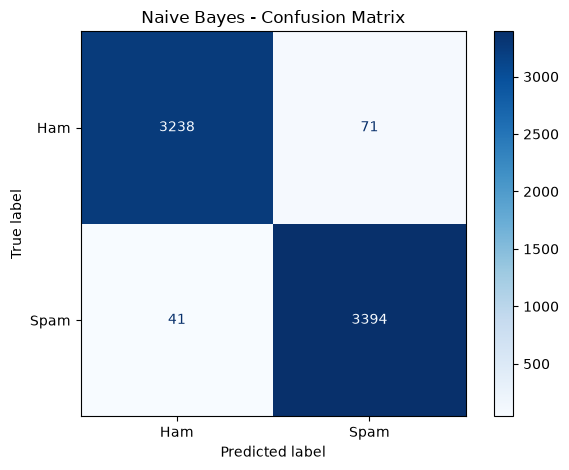

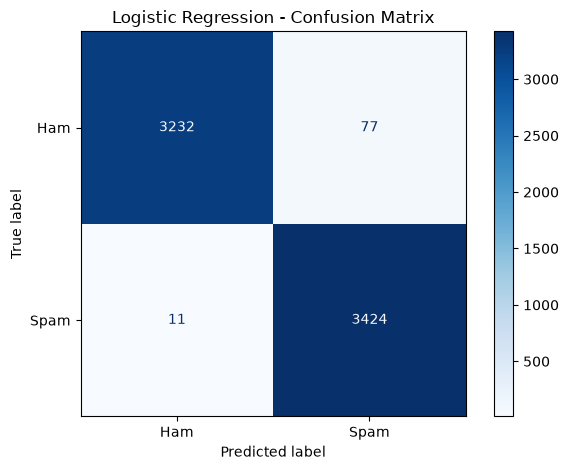

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Naive Bayes confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb,
    display_labels=["Ham", "Spam"],
    cmap="Blues",
    values_format="d"
)
plt.title("Naive Bayes - Confusion Matrix")
plt.tight_layout()
plt.savefig("naive_bayes_confusion_matrix.png", dpi=300)
plt.show()

# Logistic Regression confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=["Ham", "Spam"],
    cmap="Blues",
    values_format="d"
)
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.savefig("logistic_regression_confusion_matrix.png", dpi=300)
plt.show()

In [31]:
import joblib
import os

# Create folder for saved models
os.makedirs("models", exist_ok=True)

# Save Logistic Regression model
joblib.dump(lr_model, "models/spam_logistic_regression.pkl")

# Save fitted TF-IDF vectorizer
joblib.dump(tfidf, "models/spam_tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully!")
print("Model: models/spam_logistic_regression.pkl")
print("Vectorizer: models/spam_tfidf_vectorizer.pkl")

Model and TF-IDF vectorizer saved successfully!
Model: models/spam_logistic_regression.pkl
Vectorizer: models/spam_tfidf_vectorizer.pkl


In [32]:
import joblib

# Load saved model and TF-IDF vectorizer
loaded_model = joblib.load("models/spam_logistic_regression.pkl")
loaded_tfidf = joblib.load("models/spam_tfidf_vectorizer.pkl")

# Test email
email_text = """
Subject: Congratulations! You have won a free prize

You have been selected to receive a free cash reward.
Click here now to claim your prize.
"""

# Apply the same preprocessing used during training
cleaned_text = clean_email(email_text)
tokens = tokenize_email(cleaned_text)
filtered_tokens = remove_stopwords(tokens)
processed_text = " ".join(filtered_tokens)

# Convert email into TF-IDF features
email_features = loaded_tfidf.transform([processed_text])

# Predict email category
prediction = loaded_model.predict(email_features)[0]
probabilities = loaded_model.predict_proba(email_features)[0]

print("Email:", email_text)
print("Prediction:", "Spam" if prediction == 1 else "Ham")
print(f"Ham probability: {probabilities[0]:.2%}")
print(f"Spam probability: {probabilities[1]:.2%}")

Email: 
Subject: Congratulations! You have won a free prize

You have been selected to receive a free cash reward.
Click here now to claim your prize.

Prediction: Spam
Ham probability: 10.63%
Spam probability: 89.37%


In [33]:
# Test a normal email
ham_email = """
Subject: Meeting schedule for tomorrow

Hi Ali,

I hope you are doing well.
Our team meeting is scheduled for tomorrow at 10 AM.
Please review the project report before the meeting.

Thanks,
Ahmed
"""

# Apply the same preprocessing
cleaned_text = clean_email(ham_email)
tokens = tokenize_email(cleaned_text)
filtered_tokens = remove_stopwords(tokens)
processed_text = " ".join(filtered_tokens)

# Convert text using the saved vectorizer
email_features = loaded_tfidf.transform([processed_text])

# Predict
prediction = loaded_model.predict(email_features)[0]
probabilities = loaded_model.predict_proba(email_features)[0]

print("Prediction:", "Spam" if prediction == 1 else "Ham")
print(f"Ham probability: {probabilities[0]:.2%}")
print(f"Spam probability: {probabilities[1]:.2%}")

Prediction: Ham
Ham probability: 98.96%
Spam probability: 1.04%
